In [1]:

import numpy as np
import pandas as pd
from pathlib import Path

root = Path.home() / "Desktop/Chooser_Option_Research"

df = pd.read_csv(
    root / "02_Data/processed/W02_Feature_Dataset.csv",
    parse_dates=["Date"]
)
aligned = pd.read_csv(
    root / "02_Data/processed/W02_Aligned_Market_Data.csv",
    parse_dates=["Date"]
)

row = df.iloc[-1]
t0 = row["Date"]

S0 = float(row["Close"])
K = S0
sigma = float(row["volatility_20d"])
r1 = float(row["DGS6MO"])
r2 = float(row["DGS1"])

dividends = aligned.loc[
    (aligned["Date"] > t0 - pd.DateOffset(years=1)) &
    (aligned["Date"] <= t0), "Dividends"
].sum()

q = float(dividends / S0)

T1, T2 = 0.5, 1.0

def heston_chooser_mc(
    n_paths=20000,
    n_steps=252,
    kappa=2.0,
    xi=0.35,
    rho=-0.6,
    seed=42
):
    dt = T2 / n_steps
    choice_step = round(T1 / dt)
    assert np.isclose(choice_step * dt, T1)

    delta = T2 - T1
    forward = (r2*T2 - r1*T1) / delta

    v0 = sigma**2
    theta = v0  # Initial illustrative assumption

    rng = np.random.default_rng(seed)
    log_s = np.full(n_paths, np.log(S0))
    v = np.full(n_paths, v0)

    for step in range(n_steps):
        rate = r1 if step < choice_step else forward

        z1 = rng.standard_normal(n_paths)
        z2 = (
            rho * z1
            + np.sqrt(1 - rho**2)
            * rng.standard_normal(n_paths)
        )

        # Full-truncation variance treatment
        v_pos = np.maximum(v, 0.0)

        log_s += (
            (rate - q - 0.5*v_pos)*dt
            + np.sqrt(v_pos*dt)*z1
        )

        v += (
            kappa*(theta - v_pos)*dt
            + xi*np.sqrt(v_pos*dt)*z2
        )

        if step + 1 == choice_step:
            S_choice = np.exp(log_s.copy())

    S_expiry = np.exp(log_s)

    call_leg = np.exp(-r2*T2) * np.maximum(
        S_expiry - K, 0
    )

    adjusted_put_leg = np.exp(-r1*T1) * np.maximum(
        K*np.exp(-forward*delta)
        - S_choice*np.exp(-q*delta),
        0
    )

    discounted_values = call_leg + adjusted_put_leg

    price = discounted_values.mean()
    stderr = discounted_values.std(ddof=1) / np.sqrt(n_paths)

    return {
        "price": price,
        "stderr": stderr,
        "ci_95": (
            price - 1.96*stderr,
            price + 1.96*stderr
        )
    }

result = heston_chooser_mc()
print(result)


{'price': np.float64(28.95010385733515), 'stderr': np.float64(0.17345998031707027), 'ci_95': (np.float64(28.610122295913694), np.float64(29.290085418756608))}


In [2]:
# W04 Step 2: Heston-to-BSM consistency test

bsm_reference = 29.829018

gbm_test = heston_chooser_mc(
    n_paths=100000,
    n_steps=252,
    xi=0.0,
    seed=42
)

mc_price = float(gbm_test["price"])
mc_se = float(gbm_test["stderr"])

difference = mc_price - bsm_reference

print(f"BSM Reference:     ${bsm_reference:.4f}")
print(f"GBM Monte Carlo:   ${mc_price:.4f}")
print(f"MC Standard Error: ${mc_se:.4f}")
print(f"Difference:        ${difference:.4f}")
print(f"Difference / SE:   {difference / mc_se:.2f}")

assert abs(difference) < 4 * mc_se

print("Heston-to-BSM Consistency Test: PASSED")

BSM Reference:     $29.8290
GBM Monte Carlo:   $29.8786
MC Standard Error: $0.0900
Difference:        $0.0496
Difference / SE:   0.55
Heston-to-BSM Consistency Test: PASSED


In [3]:
# W04 Step 3: Path convergence

path_counts = [5000, 20000, 50000, 100000]

results = []

for n in path_counts:

    res = heston_chooser_mc(
        n_paths=n,
        n_steps=252,
        seed=42
    )

    results.append({
        "Paths": n,
        "Price": float(res["price"]),
        "SE": float(res["stderr"]),
        "CI Lower": float(res["ci_95"][0]),
        "CI Upper": float(res["ci_95"][1])
    })

convergence_df = pd.DataFrame(results)

display(convergence_df.round(4))

,Paths,Price,SE,CI Lower,CI Upper
0,5000,29.3010,0.3488,28.6173,29.9847
1,20000,28.9501,0.1735,28.6101,29.2901
2,50000,29.1064,0.1096,28.8915,29.3213
3,100000,28.9518,0.0770,28.8010,29.1027


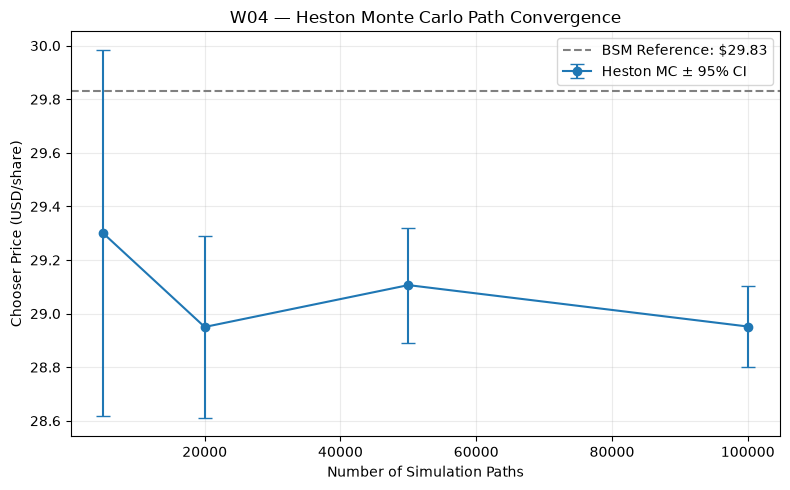

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

ax.errorbar(
    convergence_df["Paths"],
    convergence_df["Price"],
    yerr=1.96 * convergence_df["SE"],
    fmt="o-",
    capsize=5,
    label="Heston MC ± 95% CI"
)

ax.axhline(
    bsm_reference,
    linestyle="--",
    color="gray",
    label=f"BSM Reference: ${bsm_reference:.2f}"
)

ax.set_xlabel("Number of Simulation Paths")
ax.set_ylabel("Chooser Price (USD/share)")
ax.set_title("W04 — Heston Monte Carlo Path Convergence")

ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()

fig_dir = root / "04_Reports/weekly/figures"
fig_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    fig_dir / "W04_Path_Convergence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
# W04 Step 4: Time-step sensitivity

step_counts = [64, 126, 252, 504]

step_results = []

for steps in step_counts:

    res = heston_chooser_mc(
        n_paths=50000,
        n_steps=steps,
        seed=42
    )

    step_results.append({
        "Steps": steps,
        "dt": T2 / steps,
        "Price": float(res["price"]),
        "SE": float(res["stderr"])
    })

steps_df = pd.DataFrame(step_results)

display(steps_df.round(6))

,Steps,dt,Price,SE
0,64,0.015625,28.991800,0.108633
1,126,0.007937,28.998116,0.109033
2,252,0.003968,29.106373,0.109634
3,504,0.001984,29.121289,0.108879


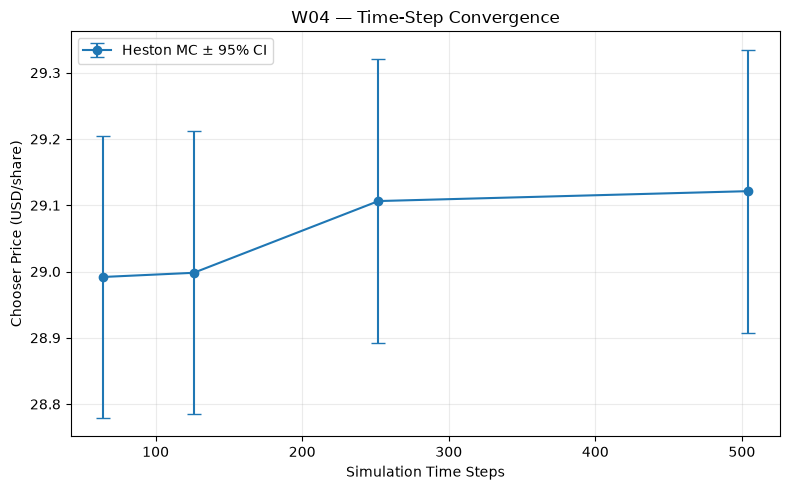

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.errorbar(
    steps_df["Steps"],
    steps_df["Price"],
    yerr=1.96 * steps_df["SE"],
    fmt="o-",
    capsize=5,
    label="Heston MC ± 95% CI"
)

ax.set_xlabel("Simulation Time Steps")
ax.set_ylabel("Chooser Price (USD/share)")
ax.set_title("W04 — Time-Step Convergence")

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()

fig.savefig(
    fig_dir / "W04_TimeStep_Convergence.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [7]:
from pathlib import Path

fig_dir = (
    Path.home()
    / "Desktop/Chooser_Option_Research/04_Reports/weekly/figures"
)

fig_dir.mkdir(parents=True, exist_ok=True)

In [8]:
fig.savefig(
    fig_dir / "W04_Path_Convergence.png",
    dpi=300,
    bbox_inches="tight"
)

In [9]:
fig.savefig(
    fig_dir / "W04_TimeStep_Convergence.png",
    dpi=300,
    bbox_inches="tight"
)

In [10]:
# W04 Step 5: Heston Parameter Sensitivity

sensitivity_specs = {
    "Vol-of-Vol": {
        "parameter": "xi",
        "values": [0.0, 0.15, 0.25, 0.35, 0.50]
    },
    "Correlation": {
        "parameter": "rho",
        "values": [-0.90, -0.70, -0.60, -0.30, 0.0]
    },
    "Mean Reversion": {
        "parameter": "kappa",
        "values": [0.5, 1.0, 2.0, 3.0, 5.0]
    }
}

sensitivity_results = []

for name, spec in sensitivity_specs.items():

    parameter = spec["parameter"]

    for value in spec["values"]:

        result = heston_chooser_mc(
            n_paths=20000,
            n_steps=252,
            seed=42,
            **{parameter: value}
        )

        sensitivity_results.append({
            "Parameter": name,
            "Value": value,
            "Price": float(result["price"]),
            "SE": float(result["stderr"])
        })

sensitivity_df = pd.DataFrame(sensitivity_results)

display(sensitivity_df.round(4))

,Parameter,Value,Price,SE
0,Vol-of-Vol,0.00,29.7147,0.2016
1,Vol-of-Vol,0.15,29.6507,0.1862
2,Vol-of-Vol,0.25,29.3823,0.1787
3,Vol-of-Vol,0.35,28.9501,0.1735
4,Vol-of-Vol,0.50,28.0798,0.1691
5,Correlation,-0.90,28.8869,0.1536
6,Correlation,-0.70,28.9378,0.1669
7,Correlation,-0.60,28.9501,0.1735
8,Correlation,-0.30,28.9317,0.1935
9,Correlation,0.00,28.8290,0.2139


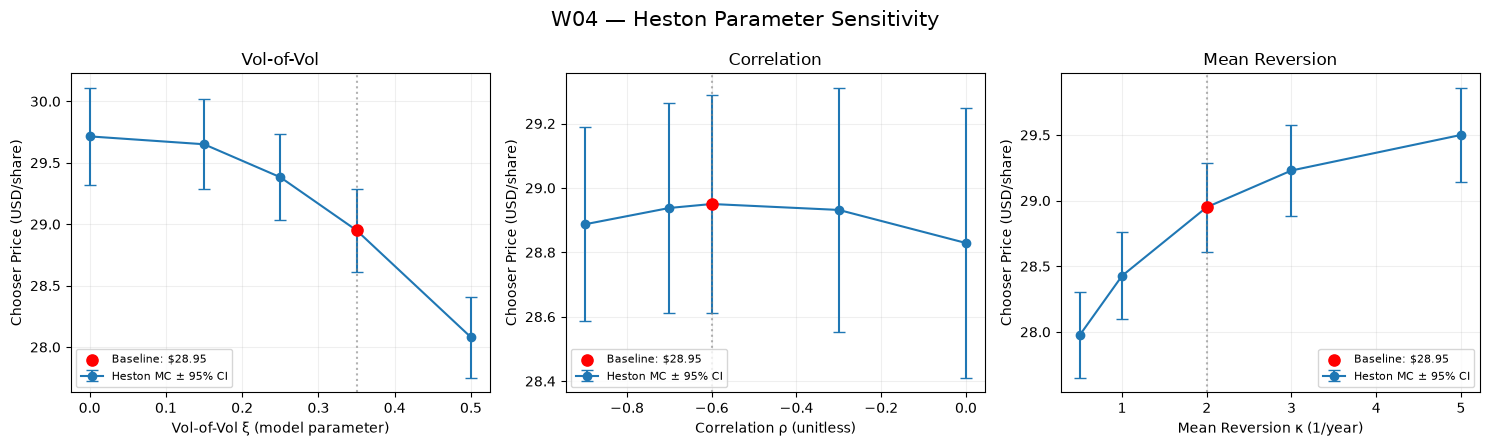

In [11]:
import matplotlib.pyplot as plt

baseline_values = {
    "Vol-of-Vol": 0.35,
    "Correlation": -0.60,
    "Mean Reversion": 2.0
}

axis_labels = {
    "Vol-of-Vol": "Vol-of-Vol ξ (model parameter)",
    "Correlation": "Correlation ρ (unitless)",
    "Mean Reversion": "Mean Reversion κ (1/year)"
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, name in zip(axes, sensitivity_specs):

    subset = sensitivity_df[
        sensitivity_df["Parameter"] == name
    ]

    ax.errorbar(
        subset["Value"],
        subset["Price"],
        yerr=1.96 * subset["SE"],
        fmt="o-",
        capsize=4,
        label="Heston MC ± 95% CI"
    )

    x0 = baseline_values[name]

    baseline_row = subset.loc[
        np.isclose(subset["Value"], x0)
    ].iloc[0]

    baseline_price = baseline_row["Price"]

    ax.scatter(
        [x0],
        [baseline_price],
        color="red",
        s=65,
        zorder=5,
        label=f"Baseline: ${baseline_price:.2f}"
    )

    ax.axvline(
        x0, linestyle=":", color="gray", alpha=0.6
    )

    ax.set_title(name)
    ax.set_xlabel(axis_labels[name])
    ax.set_ylabel("Chooser Price (USD/share)")
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)

fig.suptitle(
    "W04 — Heston Parameter Sensitivity",
    fontsize=15
)

plt.tight_layout()

In [12]:
fig_dir = (
    root / "04_Reports/weekly/figures"
)

fig_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    fig_dir / "W04_Heston_Parameter_Sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved successfully!")

Figure saved successfully!


In [13]:
# Step 7: Market Frictions Scenario Analysis

# Use a higher-path Heston estimate as the reference
base_mc = heston_chooser_mc(
    n_paths=100000,
    n_steps=252,
    kappa=2.0,
    xi=0.35,
    rho=-0.6,
    seed=42
)

mid_price = float(base_mc["price"])

# Illustrative contract assumptions
contract_multiplier = 100
fee_per_contract = 0.65

fee_per_share = fee_per_contract / contract_multiplier

friction_scenarios = [
    ("Low", 0.10, 0.00),
    ("Base", 0.25, 0.03),
    ("High", 0.50, 0.08)
]

records = []

for name, spread, slippage in friction_scenarios:

    half_spread = spread / 2

    # Additional trading cost per share
    trading_cost = (
        half_spread
        + slippage
        + fee_per_share
    )

    buy_cost = mid_price + trading_cost
    sell_proceeds = mid_price - trading_cost

    records.append({
        "Scenario": name,
        "Full Spread": spread,
        "Slippage": slippage,
        "Buy Cost": buy_cost,
        "Sell Proceeds": sell_proceeds,
        "Round-Trip Cost": 2 * trading_cost
    })

friction_df = pd.DataFrame(records)

print(f"Heston Fair Value: ${mid_price:.4f}")

display(friction_df.round(4))

Heston Fair Value: $28.9518


,Scenario,Full Spread,Slippage,Buy Cost,Sell Proceeds,Round-Trip Cost
0,Low,0.10,0.00,29.0083,28.8953,0.113
1,Base,0.25,0.03,29.1133,28.7903,0.323
2,High,0.50,0.08,29.2883,28.6153,0.673


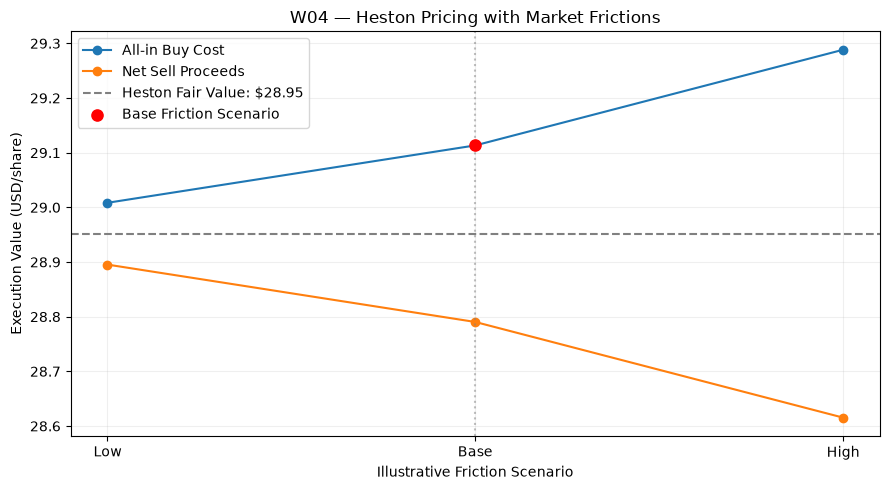

In [14]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(friction_df))

ax.plot(
    x,
    friction_df["Buy Cost"],
    "o-",
    label="All-in Buy Cost"
)

ax.plot(
    x,
    friction_df["Sell Proceeds"],
    "o-",
    label="Net Sell Proceeds"
)

ax.axhline(
    mid_price,
    color="gray",
    linestyle="--",
    label=f"Heston Fair Value: ${mid_price:.2f}"
)

# Mark Base Friction scenario
base_idx = 1

ax.axvline(
    base_idx,
    color="gray",
    linestyle=":",
    alpha=0.5
)

ax.scatter(
    [base_idx],
    [friction_df.loc[base_idx, "Buy Cost"]],
    color="red",
    s=65,
    zorder=5,
    label="Base Friction Scenario"
)

ax.set_xticks(x)
ax.set_xticklabels(friction_df["Scenario"])

ax.set_xlabel("Illustrative Friction Scenario")
ax.set_ylabel("Execution Value (USD/share)")

ax.set_title(
    "W04 — Heston Pricing with Market Frictions"
)

ax.grid(alpha=0.2)
ax.legend()

plt.tight_layout()

fig_dir = root / "04_Reports/weekly/figures"
fig_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    fig_dir / "W04_Market_Frictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()